# boundary_layer — 최적화 전 / 후 시간 측정 (strong · weak scaling)

`main_scale.cpp`(= main.cpp + 구간 타이머, `tools/scale/instrument_main.py` 생성) 로 잰 시간 루프의 호출 단위 구간. ms/step(랭크 max), 200 스텝 중 앞 50 스텝 제외, 반복 중 step_total 중앙값 런.

- **before** = 최적화 전 원본 커밋(f330720)의 코드로 빌드한 `build_gpu/bin/orig/boundary_layer_scale`
- **after** = 현재 코드 `build_gpu/bin/boundary_layer_scale`
- 덱 `scale/decks/input_{strong,weak}_256_np{N}.ini`: strong 256³ 고정, weak 256³/rank. 기종·노드는 `scale/out/environment_*.txt` 에서 읽어 제목에 적는다. **그림 저장 없음.**

§A 전(이벤트별 막대, np 나란히) · §B 후 · §C 이벤트별 scaling 곡선에 전(큰 빈 ○, 파선)·후(작은 채운 ■, 실선) 겹치기 · §D 전 vs 후 이벤트별 감소량 + 요약표

In [ ]:
import csv, glob, os, re
from collections import defaultdict
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullFormatter, PercentFormatter
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "legend.fontsize": 8, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
OUT_DIR = os.path.join(os.getcwd(), "scale", "out")
SAVE_FIG = False   # 항상 끔
NP_COLOR = {1: "#bcd3f0", 2: "#7fa9e3", 4: "#2a78d6", 8: "#164a8a"}
STYLE = {"before": dict(marker="o", ls="--", mfc="white", ms=10, mew=1.6, z=2), "after": dict(marker="s", ls="-", mfc=None, ms=5, mew=1.2, z=3)}
COLOR = {"before": "#9a9a96", "after": "#2a78d6"}

def load(variant):
    """{(mode, n, np): 대표 런(dict phase→ms)} — 반복 중 step_total 중앙값"""
    runs = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(OUT_DIR, f"*_{variant}_*_r*.csv"))):
        m = re.search(r"(strong|weak)_(\d+)_np(\d+)_%s_(\d+)_r(\d+)\.csv$" % variant, path)
        if not m: continue
        ph = {}
        with open(path) as fh:
            for row in csv.reader(l for l in fh if not l.startswith("#")):
                if row and row[0] != "phase":
                    ph[row[0]] = float(row[3])
        if "step_total" not in ph: continue
        ph["_job"] = m.group(4)
        runs[(m.group(1), int(m.group(2)), int(m.group(3)))].append(ph)
    return {k: sorted(v, key=lambda r: r["step_total"])[len(v) // 2] for k, v in runs.items()}

def describe(jobs):
    hosts, names, ngpu = [], [], 0
    for f in sorted(glob.glob(os.path.join(OUT_DIR, "environment_*.txt"))):
        if re.search(r"_(\d+)\.txt$", f).group(1) not in jobs: continue
        txt = open(f).read()
        h = re.search(r"host=(\S+)", txt)
        if h and h.group(1) not in hosts: hosts.append(h.group(1))
        gl = [l.split(",")[0].strip() for l in txt.splitlines() if l.startswith(("NVIDIA", "Tesla"))]
        if gl:
            ngpu = max(ngpu, len(gl))
            if gl[0] not in names: names.append(gl[0])
    return f"{'/'.join(names) or '?'} x{ngpu} @ {'/'.join(hosts) or '?'}"

BEFORE, AFTER = load("orig"), load("new")
HW = {lab: describe({r["_job"] for r in cases.values()}) for lab, cases in (("before", BEFORE), ("after", AFTER))}
EVENTS = sorted({e for cases in (BEFORE, AFTER) for r in cases.values() for e in r if not e.startswith("_") and "." not in e and e != "step_total"},
                key=lambda e: -max(r.get(e, 0) for r in list(BEFORE.values()) + list(AFTER.values())))
for lab, cases in (("before", BEFORE), ("after", AFTER)):
    print(f"[{lab}] {HW[lab]} — {len(cases)} cases")
    for k in sorted(cases):
        print(f"    {k[0]:6s} {k[1]}^3 np{k[2]:<2d}  step_total {cases[k]['step_total']:8.2f} ms/step")
print("events:", EVENTS)

[before] Tesla V100-SXM2-32GB x8 @ gpu01/gpu04 — 8 cases
    strong 256^3 np1   step_total   124.79 ms/step
    strong 256^3 np2   step_total    62.36 ms/step
    strong 256^3 np4   step_total    39.58 ms/step
    strong 256^3 np8   step_total    42.19 ms/step
    weak   256^3 np1   step_total   124.95 ms/step
    weak   256^3 np2   step_total   138.13 ms/step
    weak   256^3 np4   step_total   147.33 ms/step
    weak   256^3 np8   step_total   186.17 ms/step
[after] Tesla V100-SXM2-32GB x8 @ gpu01/gpu04 — 8 cases
    strong 256^3 np1   step_total    64.44 ms/step
    strong 256^3 np2   step_total    39.75 ms/step
    strong 256^3 np4   step_total    28.60 ms/step
    strong 256^3 np8   step_total    33.09 ms/step
    weak   256^3 np1   step_total    64.35 ms/step
    weak   256^3 np2   step_total    75.06 ms/step
    weak   256^3 np4   step_total    79.63 ms/step
    weak   256^3 np8   step_total    90.32 ms/step
events: ['momentum_solve', 'pressure_solve', 'sync_UVW', 'momentum_rhs'

In [ ]:
def plot_event_bars(cases, label, mode, n):
    keys = sorted(k for k in cases if k[:2] == (mode, n))
    if not keys: return
    fig, ax = plt.subplots(figsize=(12.5, 4.0)); nps = [k[2] for k in keys]; xs = np.arange(len(EVENTS)); w = 0.8 / len(nps)
    base = np.array([cases[keys[0]].get(e, 0) for e in EVENTS]); vmax = base.max()
    for j, k in enumerate(keys):
        vals = np.array([cases[k].get(e, 0) for e in EVENTS]); vmax = max(vmax, vals.max()); pos = xs - 0.4 + w * (j + 0.5)
        ax.bar(pos, vals, w * 0.92, color=NP_COLOR.get(k[2], "#164a8a"), label=f"np {k[2]}  (step_total {cases[k]['step_total']:.1f} ms)")
        if j > 0:
            for x, v, b in zip(pos, vals, base):
                if b > 0.02 * base.max(): ax.annotate(f"{v / b:.2f}", (x, v), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=6.3, color="#52514e", rotation=90)
    ax.set_xticks(xs); ax.set_xticklabels(EVENTS, rotation=40, ha="right"); ax.set_ylabel("ms / step (rank max)")
    ax.set_title(f"[{label}] {HW[label]} — {mode} {n}³: events by np (number = ratio to np {nps[0]})", fontsize=10, loc="left")
    ax.set_ylim(0, vmax * 1.15); ax.legend(frameon=False, ncol=len(nps), loc="upper center", bbox_to_anchor=(0.5, -0.5), fontsize=7.5); plt.tight_layout()

def plot_event_scaling(mode, n):
    versions = [(BEFORE, "before"), (AFTER, "after")]
    nps_all = sorted({k[2] for cases, _ in versions for k in cases if k[:2] == (mode, n)})
    if not nps_all: return
    evs = ["step_total"] + EVENTS; ncol = 5; nrow = int(np.ceil(len(evs) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13.5, 2.6 * nrow))
    for ax, e in zip(axes.flat, evs):
        for cases, label in versions:
            ks = sorted(k for k in cases if k[:2] == (mode, n))
            if not ks: continue
            nps = np.array([k[2] for k in ks]); t = np.array([cases[k].get(e, 0) for k in ks]); st = STYLE[label]; c = COLOR[label]
            ax.plot(nps, t, color=c, marker=st["marker"], ls=st["ls"], mfc=st["mfc"] or c, ms=st["ms"], mew=st["mew"], zorder=st["z"], label=label)
            if t[0] > 0:
                ideal = t[0] * nps[0] / nps if mode == "strong" else np.full_like(t, t[0]); ax.plot(nps, ideal, color=c, ls=":", lw=0.8, alpha=0.6)
        ax.set_xscale("log", base=2); ax.xaxis.set_major_locator(FixedLocator(nps_all)); ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xticklabels([str(v) for v in nps_all])
        if mode == "strong": ax.set_yscale("log")
        ax.set_title(e, fontsize=9); ax.tick_params(labelsize=7)
    for ax in list(axes.flat)[len(evs):]: ax.axis("off")
    axes.flat[0].legend(frameon=False, fontsize=7)
    fig.suptitle(f"{mode} {n}³ — events vs np: before ({HW['before']}) ○ dashed vs after ({HW['after']}) ■ solid, dotted = ideal", fontsize=10, x=0.01, ha="left")
    fig.tight_layout()

def plot_before_after(mode, n, np_):
    k = (mode, n, np_)
    if k not in BEFORE or k not in AFTER: return
    b, a = BEFORE[k], AFTER[k]; evs = ["step_total"] + EVENTS
    vb = np.array([b.get(e, 0) for e in evs]); va = np.array([a.get(e, 0) for e in evs])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.0), gridspec_kw={"width_ratios": [1.15, 1]}); xs = np.arange(len(evs)); w = 0.38
    ax1.bar(xs - w / 2, vb, w, color=COLOR["before"], label=f"before  step_total {b['step_total']:.1f} ms"); ax1.bar(xs + w / 2, va, w, color=COLOR["after"], label=f"after  step_total {a['step_total']:.1f} ms")
    ax1.set_xticks(xs); ax1.set_xticklabels(evs, rotation=40, ha="right"); ax1.set_ylabel("ms / step (rank max)")
    ax1.set_title(f"{HW['after']} — {mode} {n}³, np {np_}: before vs after", fontsize=10, loc="left"); ax1.set_ylim(0, max(vb.max(), va.max()) * 1.12); ax1.legend(frameon=False, fontsize=7.5)
    d = vb - va; ax2.bar(xs, d, 0.62, color=["#2a78d6" if v >= 0 else "#e34948" for v in d])
    for x, v, bv in zip(xs, d, vb):
        if bv > 0.02 * vb.max(): ax2.annotate(f"{100 * v / bv:+.0f}%", (x, v), xytext=(0, 2 if v >= 0 else -9), textcoords="offset points", ha="center", fontsize=6.5, color="#52514e", rotation=90)
    ax2.axhline(0, color="#52514e", lw=0.8); ax2.set_xticks(xs); ax2.set_xticklabels(evs, rotation=40, ha="right"); ax2.set_ylabel("reduction = before − after (ms / step)")
    ax2.set_title(f"reduction per event (step_total {b['step_total']:.1f} → {a['step_total']:.1f} ms, {100*(1-a['step_total']/b['step_total']):+.0f}%)", fontsize=10, loc="left"); fig.tight_layout()
print("plot helpers ready")

plot helpers ready


## A. 최적화 전 — 이벤트별 막대(np 나란히)

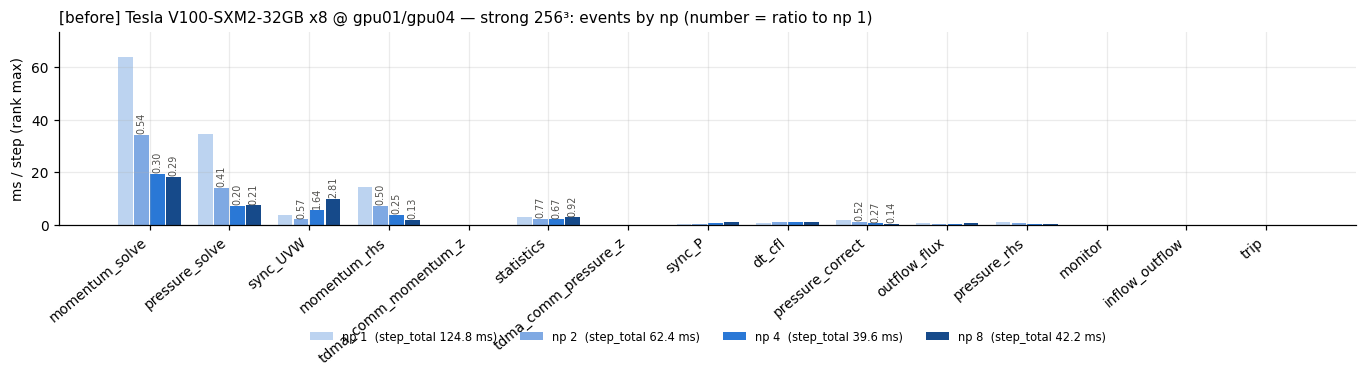

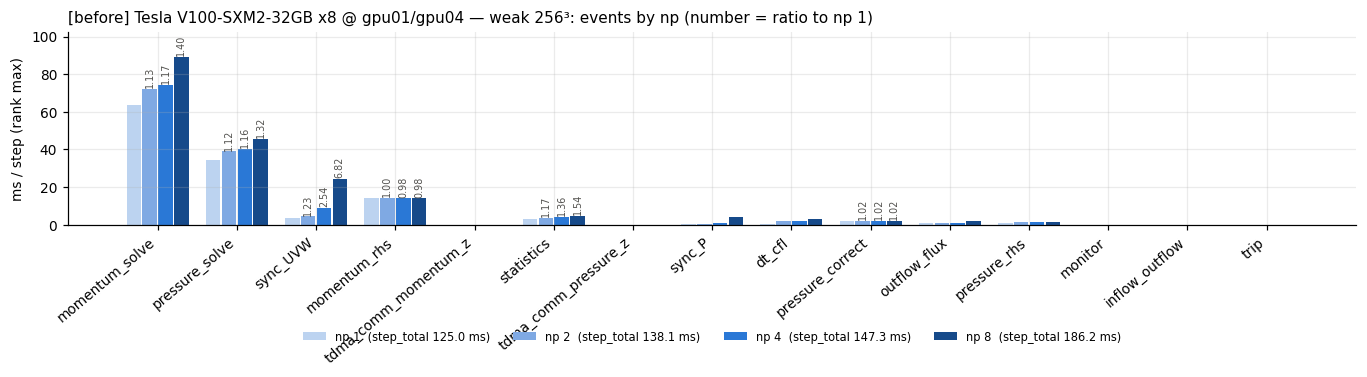

In [ ]:
for mode in ("strong", "weak"):
    plot_event_bars(BEFORE, "before", mode, 256)
plt.show()

## B. 최적화 후 — 이벤트별 막대

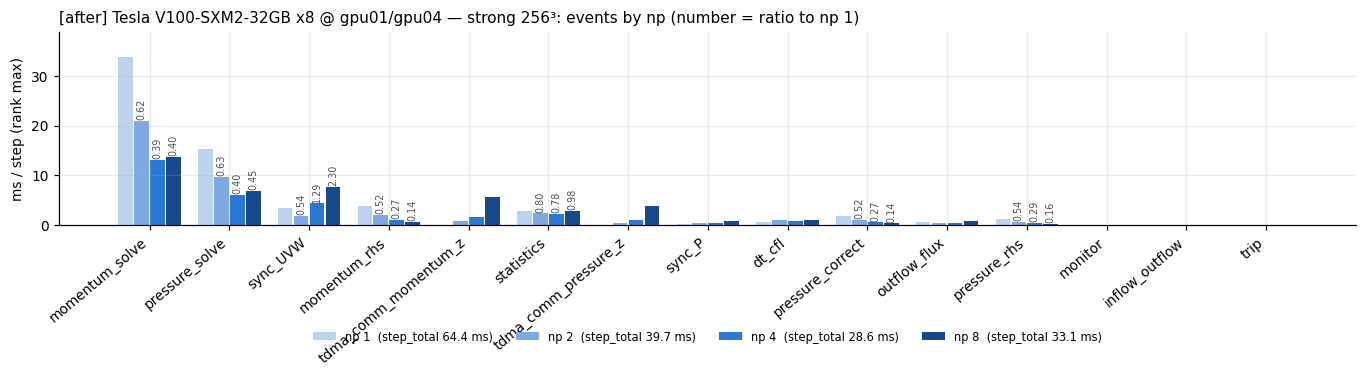

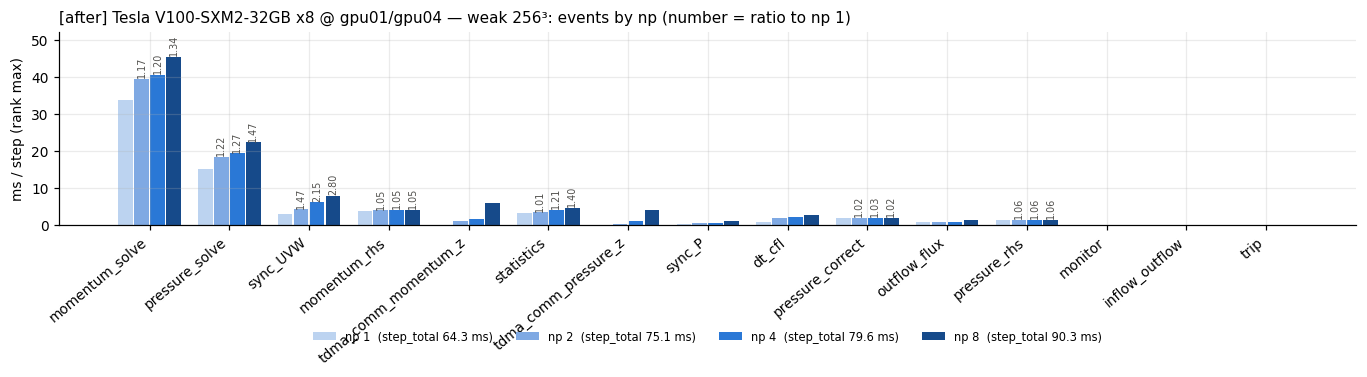

In [ ]:
for mode in ("strong", "weak"):
    plot_event_bars(AFTER, "after", mode, 256)
plt.show()

## C. 이벤트별 scaling 곡선 — 전(○ 파선, 빈 마커) vs 후(■ 실선, 채운 마커), 점선 = 이상선

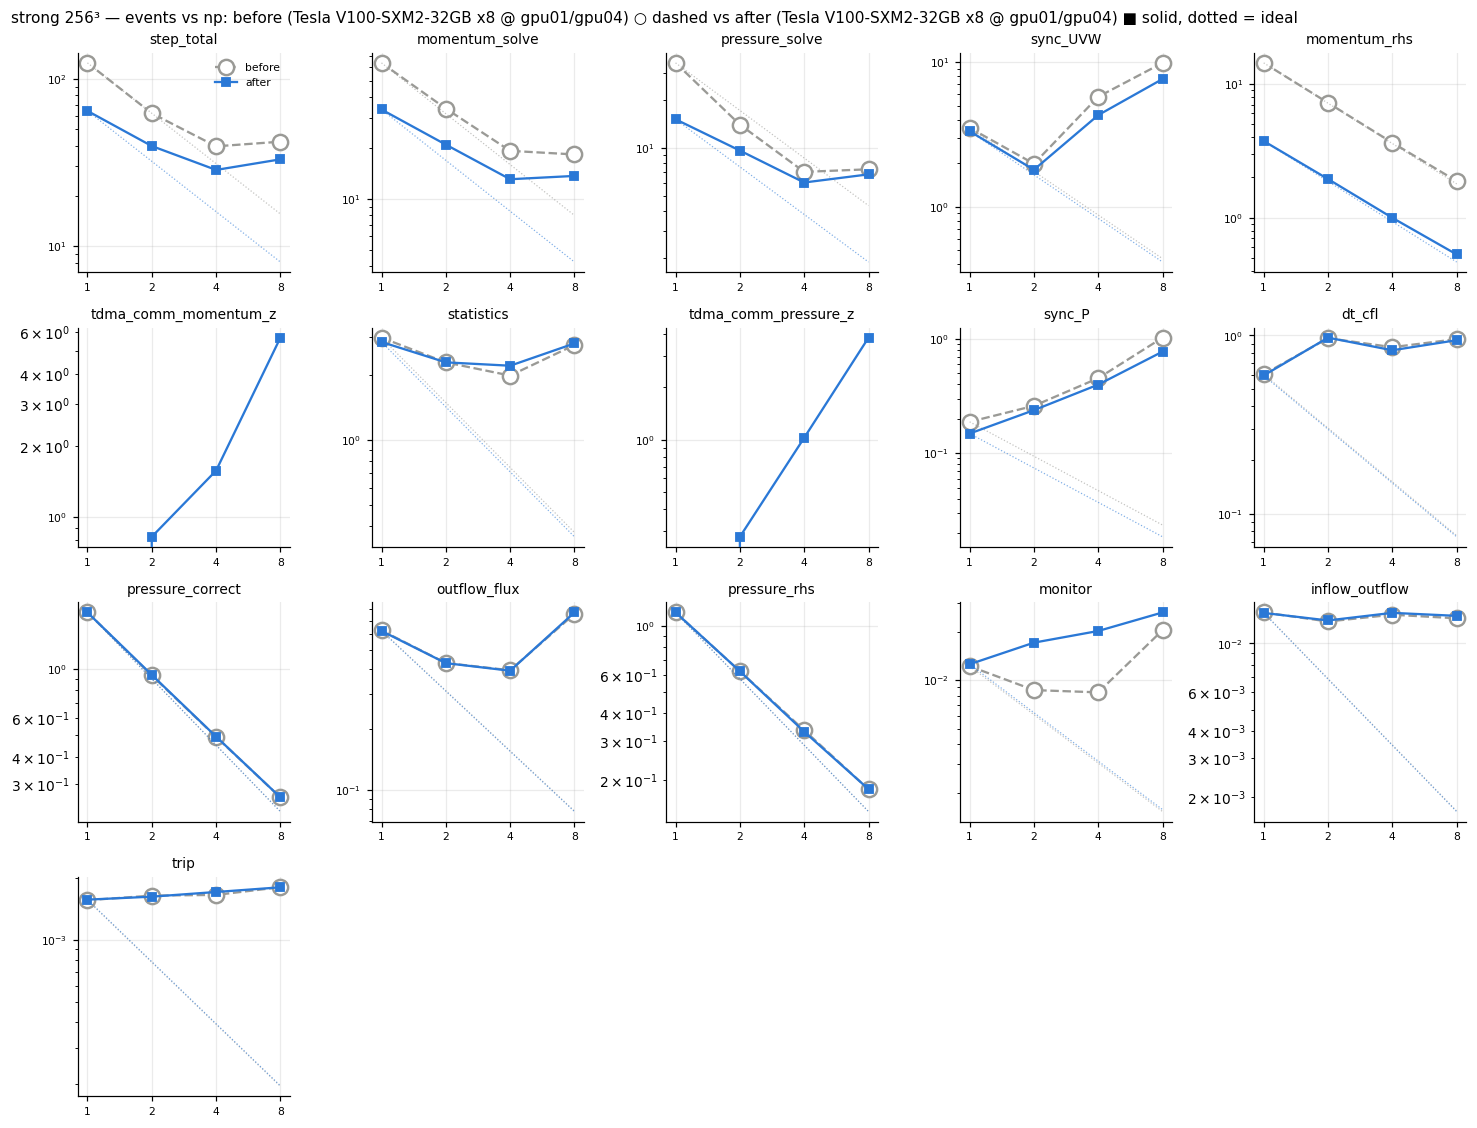

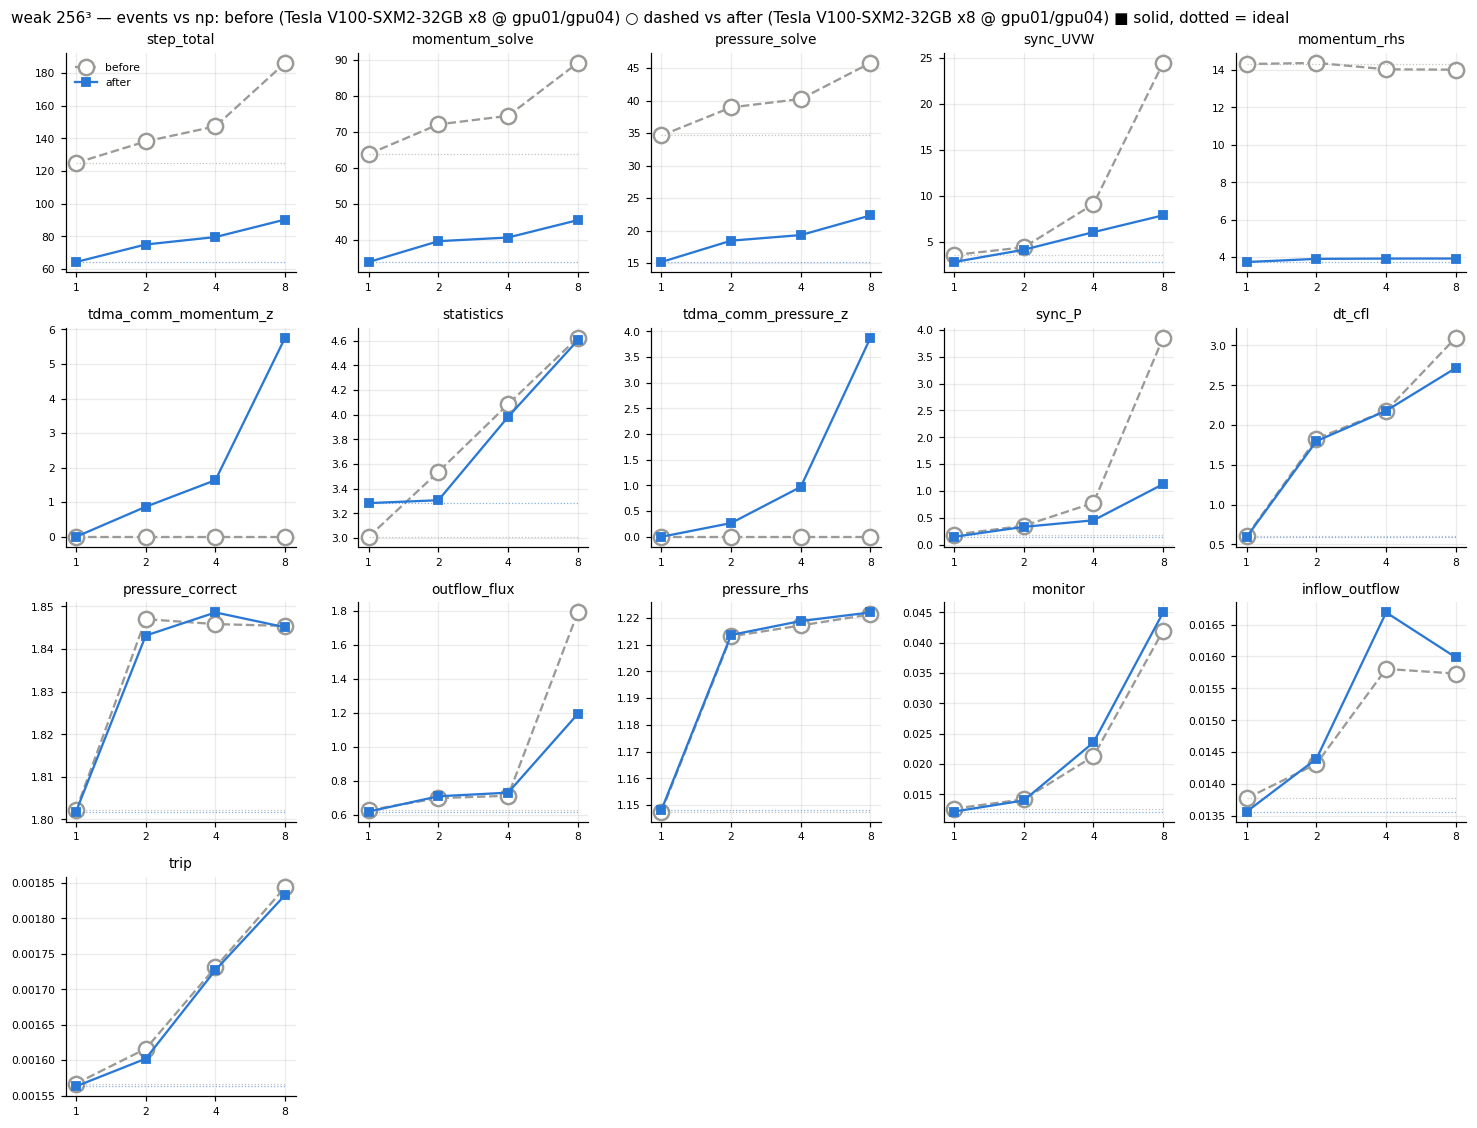

In [ ]:
for mode in ("strong", "weak"):
    plot_event_scaling(mode, 256)
plt.show()

## D. 전 vs 후 — 같은 문제 크기·np 에서 이벤트별 시간과 감소량 + 요약표

mode   np  |   before    after   gain  speedup | eff before eff after | 가장 많이 줄어든 이벤트 (ms)
strong 1   |    124.8     64.4    48%    1.94x |       100%      100% | momentum_solve −30.0, pressure_solve −19.4, momentum_rhs −10.6
strong 2   |     62.4     39.7    36%    1.57x |       100%       81% | momentum_solve −13.3, momentum_rhs −5.3, pressure_solve −4.4
strong 4   |     39.6     28.6    28%    1.38x |        79%       56% | momentum_solve −6.2, momentum_rhs −2.6, sync_UVW −1.5
strong 8   |     42.2     33.1    22%    1.27x |        37%       24% | momentum_solve −4.7, sync_UVW −2.2, momentum_rhs −1.3
weak   1   |    125.0     64.3    49%    1.94x |       100%      100% | momentum_solve −30.0, pressure_solve −19.5, momentum_rhs −10.6
weak   2   |    138.1     75.1    46%    1.84x |        90%       86% | momentum_solve −32.5, pressure_solve −20.5, momentum_rhs −10.5
weak   4   |    147.3     79.6    46%    1.85x |        85%       81% | momentum_solve −33.8, pressure_solve −20.9, mom

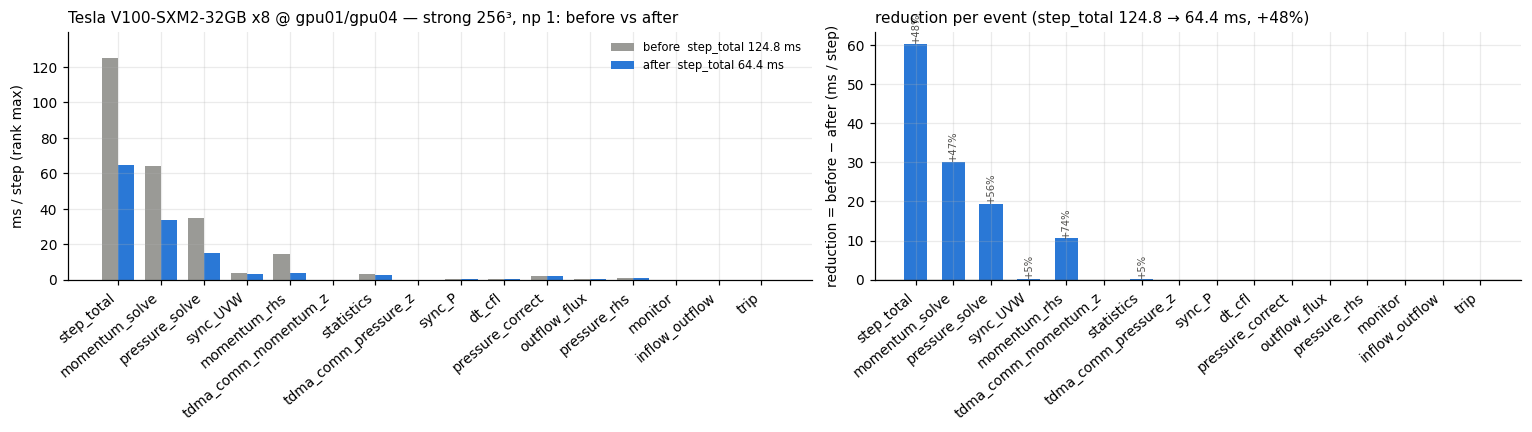

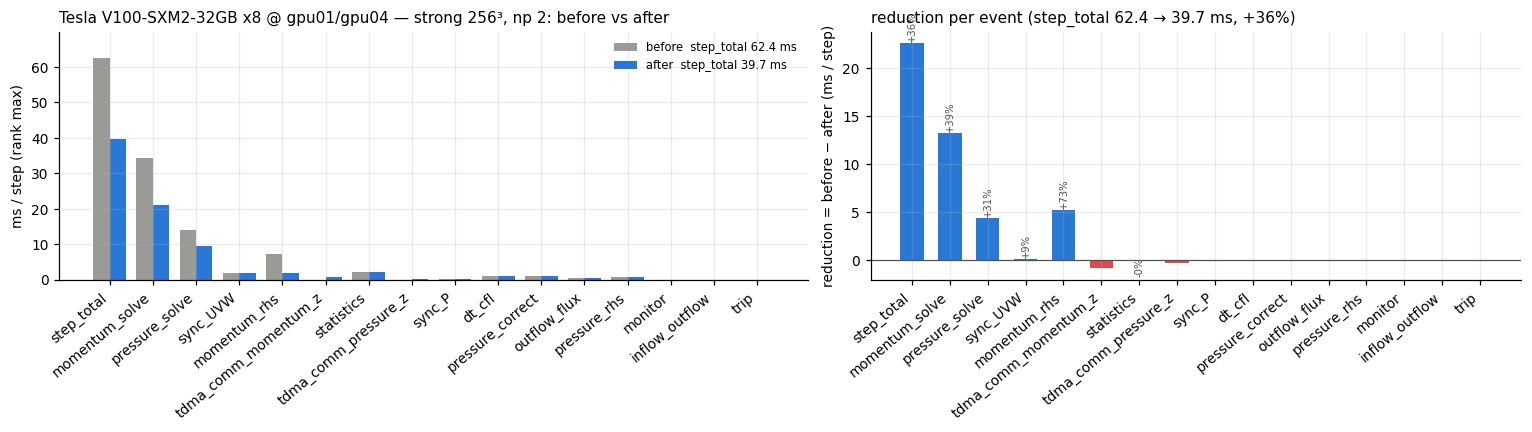

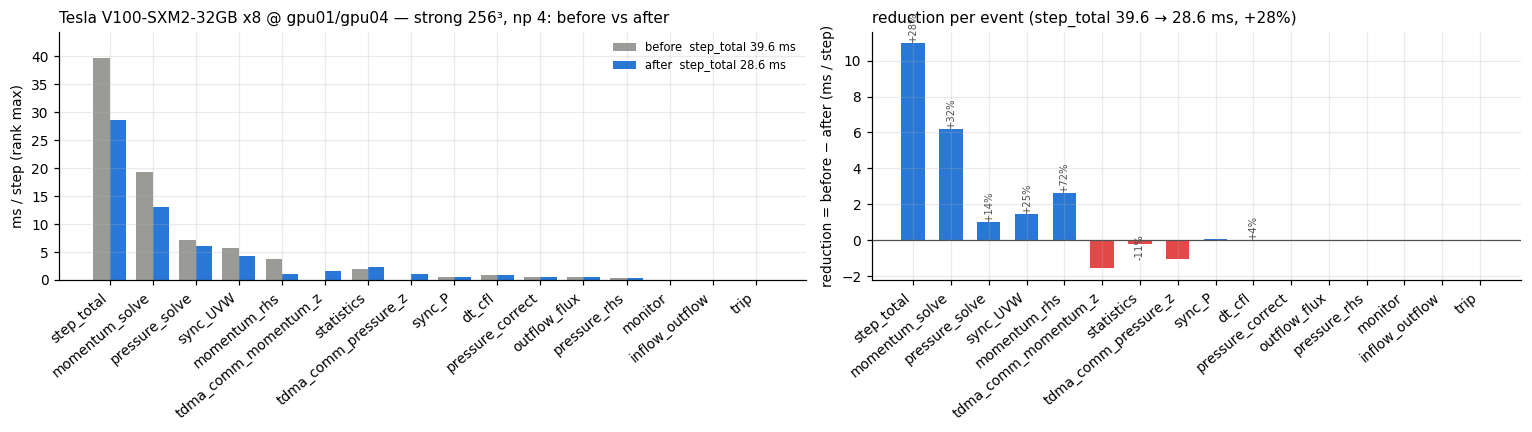

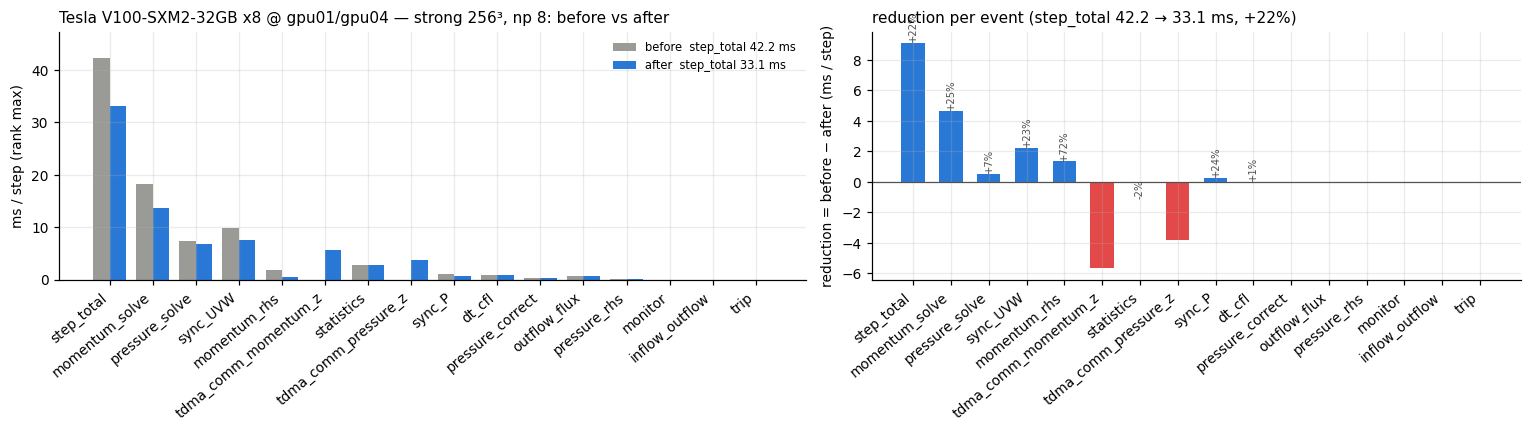

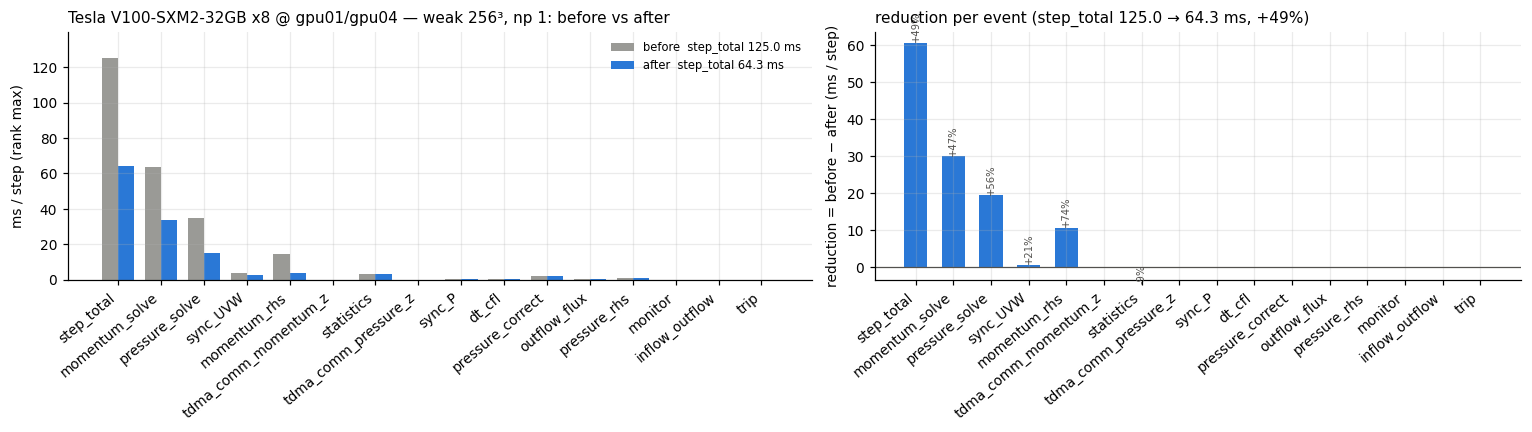

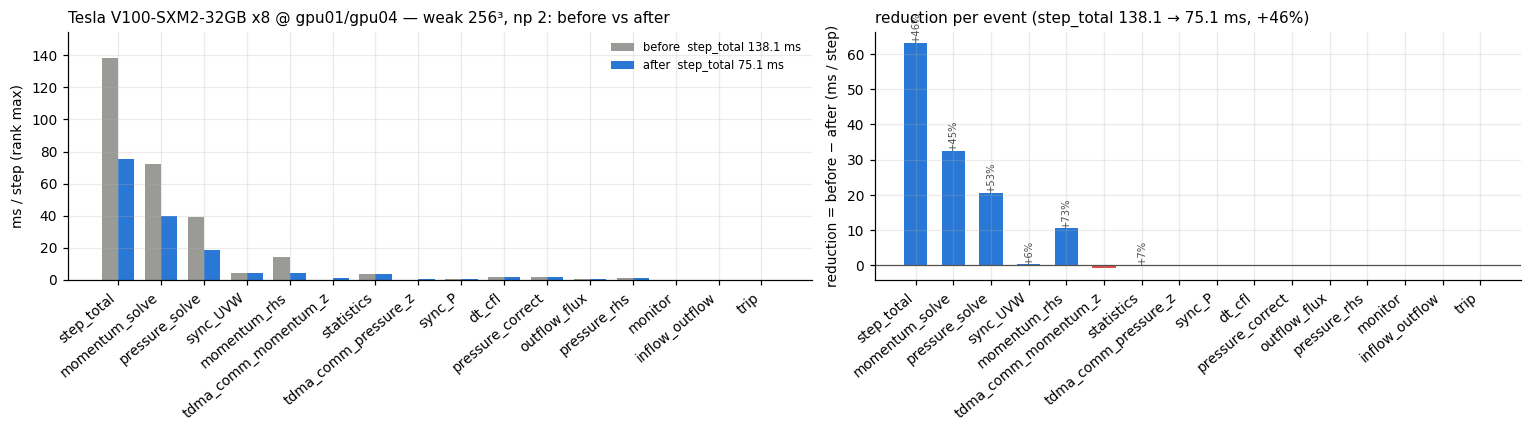

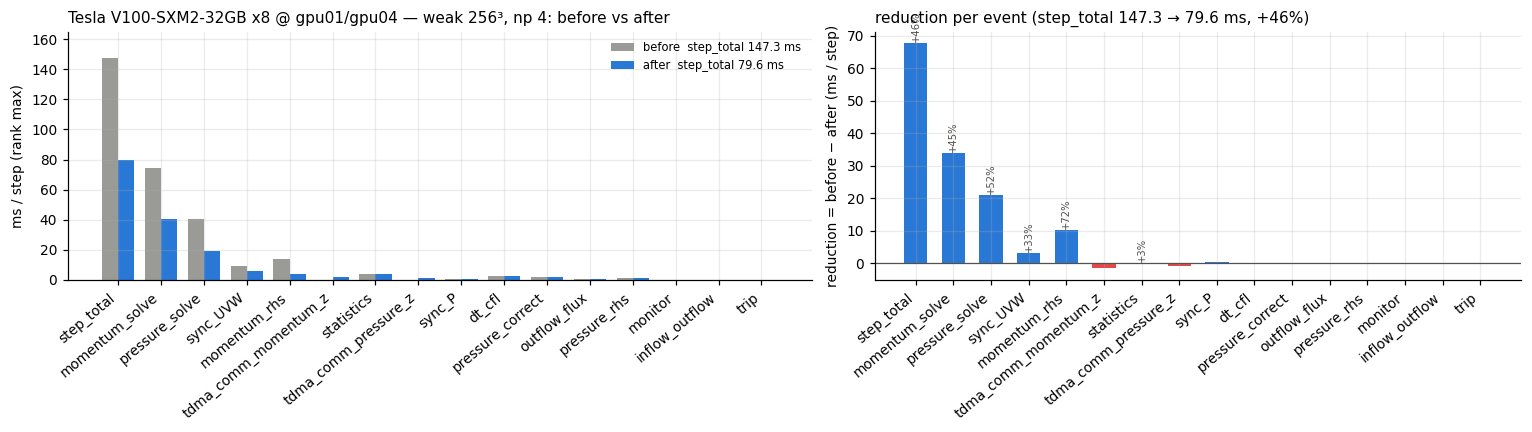

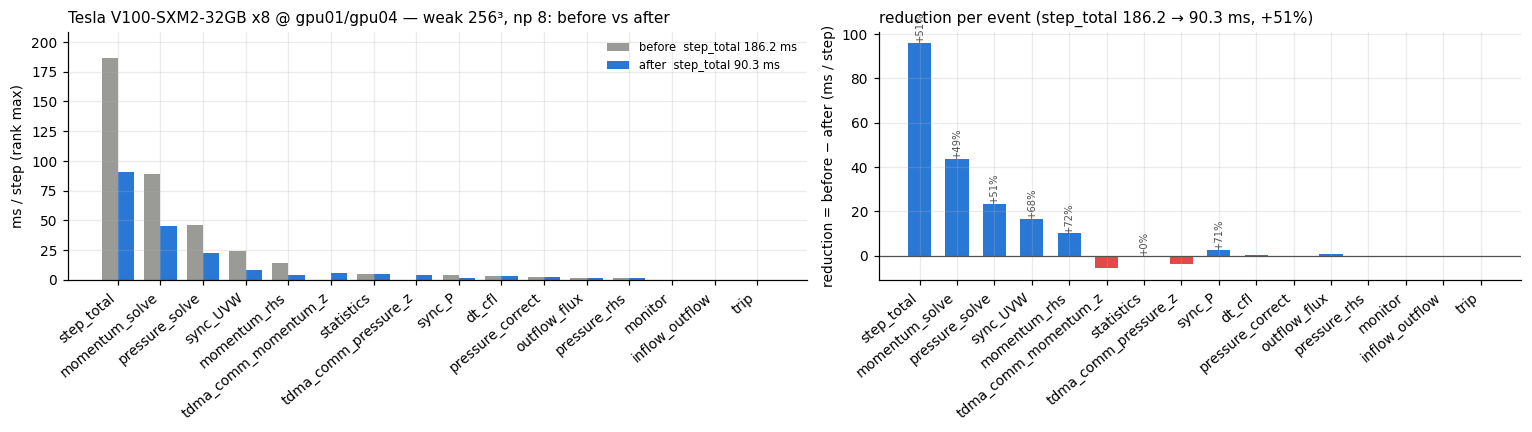

In [ ]:
for mode in ("strong", "weak"):
    for np_ in (1, 2, 4, 8):
        plot_before_after(mode, 256, np_)
plt.show()
print(f"{'mode':6s} {'np':3s} | {'before':>8s} {'after':>8s} {'gain':>6s} {'speedup':>8s} | {'eff before':>10s} {'eff after':>9s} | 가장 많이 줄어든 이벤트 (ms)")
for mode in ("strong", "weak"):
    for np_ in (1, 2, 4, 8):
        k = (mode, 256, np_)
        if k not in BEFORE or k not in AFTER: continue
        b, a = BEFORE[k], AFTER[k]; k1 = (mode, 256, 1)
        def eff(cases):
            if k1 not in cases: return float("nan")
            t1, t = cases[k1]["step_total"], cases[k]["step_total"]
            return 100 * (t1 / (t * np_) if mode == "strong" else t1 / t)
        d = sorted(((b.get(e, 0) - a.get(e, 0), e) for e in EVENTS), reverse=True)[:3]
        print(f"{mode:6s} {np_:<3d} | {b['step_total']:8.1f} {a['step_total']:8.1f} {100*(1-a['step_total']/b['step_total']):5.0f}% {b['step_total']/a['step_total']:7.2f}x | {eff(BEFORE):9.0f}% {eff(AFTER):8.0f}% | " + ", ".join(f"{e} −{v:.1f}" for v, e in d))